
✓ Success! Side-by-side subplots with shared Y-axis saved to: /work/scratch/rawat/models/microsam_training_output/logs/vit_b_lm_patch1024_0.001percentile/mid_thesis_loss_subplots_shared_y.png


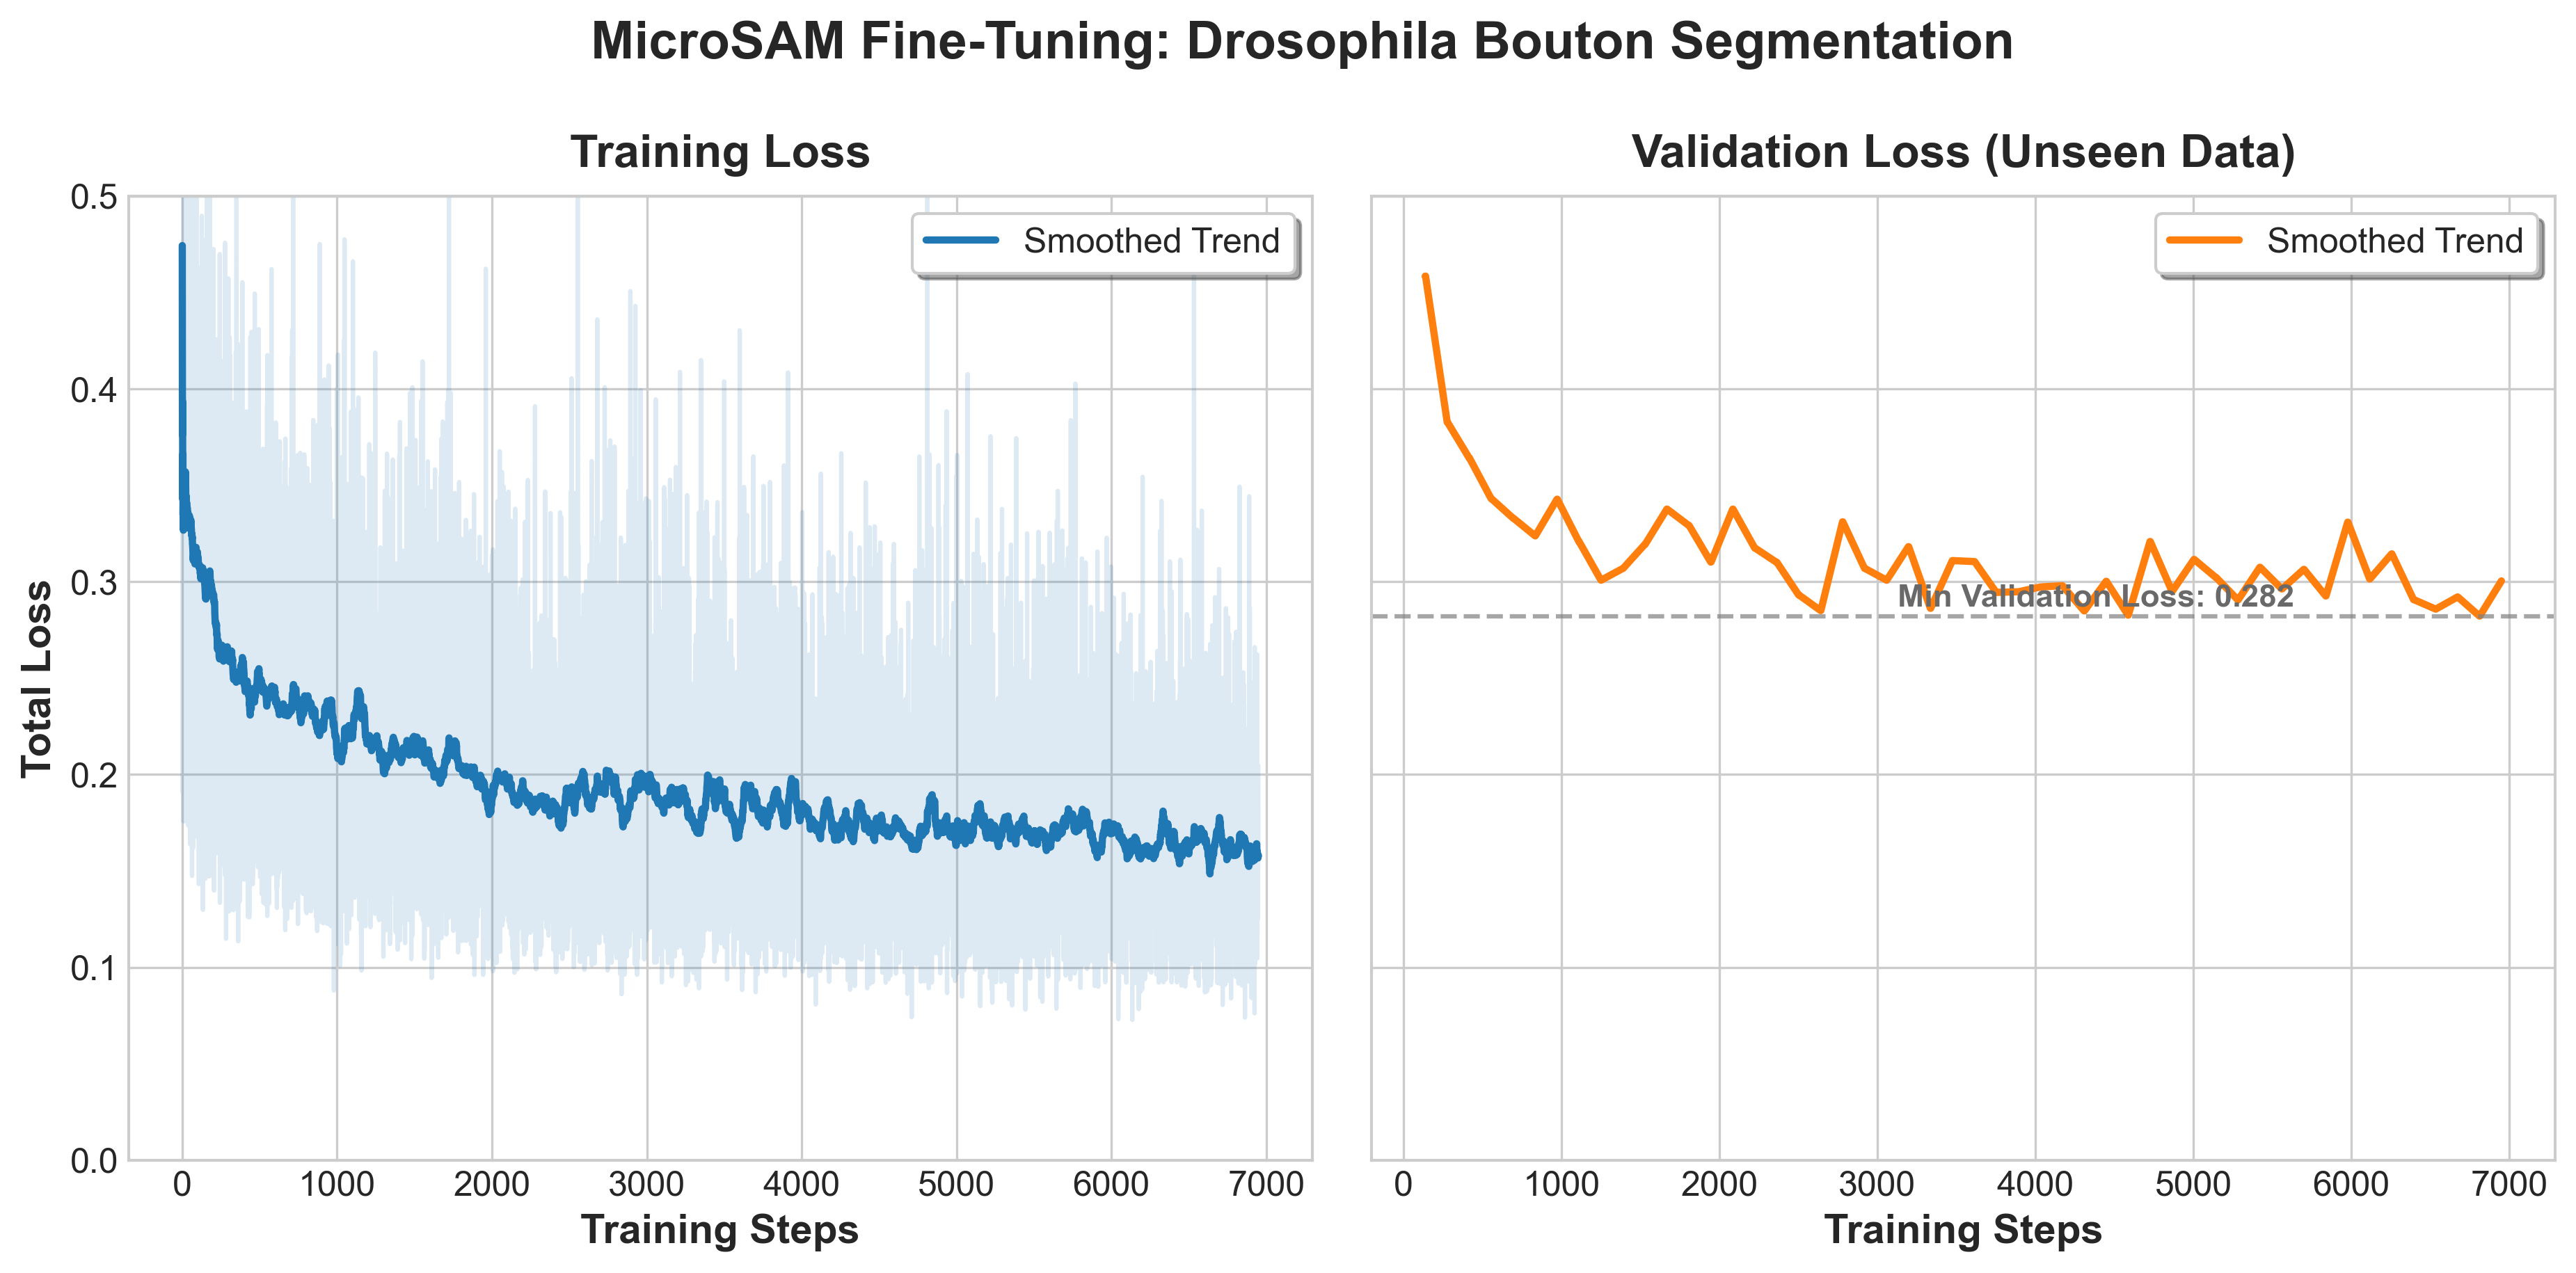

In [5]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ==========================================
# 1. CONFIGURATION
# ==========================================
LOG_DIR = r"/work/scratch/rawat/models/microsam_training_output/logs/vit_b_lm_patch1024_0.001percentile"
SMOOTHING_WINDOW = 50 
OUTPUT_FILENAME = "mid_thesis_loss_subplots_shared_y.png"

# ==========================================
# 2. DATA EXTRACTION FUNCTION
# ==========================================
def extract_metric(event_files, metric_name):
    all_steps, all_values = [], []
    
    for file in event_files:
        ea = EventAccumulator(file)
        ea.Reload()
        if 'scalars' in ea.Tags() and metric_name in ea.Tags()['scalars']:
            for event in ea.Scalars(metric_name):
                all_steps.append(event.step)
                all_values.append(event.value)
    
    if not all_steps:
        return pd.DataFrame()
        
    sorted_data = sorted(zip(all_steps, all_values))
    steps, values = zip(*sorted_data)
    
    df = pd.DataFrame({'Step': steps, metric_name: values})
    df = df.drop_duplicates(subset='Step', keep='last')
    return df

# ==========================================
# 3. LOAD AND PROCESS DATA
# ==========================================
event_files = glob.glob(os.path.join(LOG_DIR, "**", "*tfevents*"), recursive=True)

df_train = extract_metric(event_files, 'train/loss')
df_val = extract_metric(event_files, 'validation/loss')

# Merge dataframes
df = pd.merge(df_train, df_val, on='Step', how='outer').sort_values('Step')

# Calculate the moving average
df['Train_Smooth'] = df['train/loss'].rolling(window=SMOOTHING_WINDOW, min_periods=1).mean()
# Validation has fewer points, so we use a smaller window or just connect the dots. 
# Using a smaller window (e.g., 3) for validation since it's only 50 epochs.
df['Val_Smooth'] = df['validation/loss'].rolling(window=3, min_periods=1).mean()

# ==========================================
# 4. ACADEMIC GRAPH FORMATTING (SIDE-BY-SIDE)
# ==========================================
plt.style.use('seaborn-v0_8-whitegrid')

# sharey=True forces both graphs to have the exact same Y-axis scale
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=300, sharey=True)

# ------------------------------------------
# LEFT PLOT: Training Loss
# ------------------------------------------
# Drop NaNs just for plotting to ensure continuous lines
train_clean = df.dropna(subset=['train/loss'])
train_smooth_clean = df.dropna(subset=['Train_Smooth'])

ax1.plot(train_clean['Step'], train_clean['train/loss'], alpha=0.15, color='#1f77b4', linestyle='-')
ax1.plot(train_smooth_clean['Step'], train_smooth_clean['Train_Smooth'], color='#1f77b4', linewidth=2.5, label='Smoothed Trend')

ax1.set_title("Training Loss", fontsize=16, fontweight='bold', pad=10)
ax1.set_xlabel("Training Steps", fontsize=14, fontweight='bold')
ax1.set_ylabel("Total Loss", fontsize=14, fontweight='bold')
ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.legend(loc='upper right', frameon=True, fontsize=12, shadow=True)

# ------------------------------------------
# RIGHT PLOT: Validation Loss
# ------------------------------------------
# Drop NaNs here to fix the "floating points" issue and create a solid line
val_clean = df.dropna(subset=['validation/loss'])
val_smooth_clean = df.dropna(subset=['Val_Smooth'])

ax2.plot(val_clean['Step'], val_clean['validation/loss'], alpha=0.25, color='#ff7f0e', linestyle='-')
ax2.plot(val_smooth_clean['Step'], val_smooth_clean['Val_Smooth'], color='#ff7f0e', linewidth=2.5, label='Smoothed Trend')

# Add minimum validation loss annotation
min_val_loss = val_smooth_clean['Val_Smooth'].min()
ax2.axhline(y=min_val_loss, color='gray', linestyle='--', alpha=0.7)
ax2.text(val_clean['Step'].max() * 0.45, min_val_loss + 0.005, 
        f'Min Validation Loss: {min_val_loss:.3f}', 
        color='dimgray', fontsize=11, fontweight='bold')

ax2.set_title("Validation Loss (Unseen Data)", fontsize=16, fontweight='bold', pad=10)
ax2.set_xlabel("Training Steps", fontsize=14, fontweight='bold')
ax2.tick_params(axis='both', which='major', labelsize=12)
ax2.legend(loc='upper right', frameon=True, fontsize=12, shadow=True)
plt.ylim(0, 0.5)  # Add here

# ------------------------------------------
# FINAL FIGURE ADJUSTMENTS
# ------------------------------------------
fig.suptitle("MicroSAM Fine-Tuning: Drosophila Bouton Segmentation", 
             fontsize=18, fontweight='bold', y=1.02)

# Reduce the gap between the two plots
plt.subplots_adjust(wspace=0.05)

save_path = os.path.join(LOG_DIR, OUTPUT_FILENAME)
plt.savefig(save_path, bbox_inches='tight')

print(f"\n✓ Success! Side-by-side subplots with shared Y-axis saved to: {save_path}")